<style>
@media print {
    pre, code {
        white-space: pre-wrap !important;
        overflow-wrap: anywhere !important;
        word-wrap: break-word !important;
    }

    table {
        width: 100% !important;
        table-layout: fixed !important;
    }

    th, td {
        white-space: normal !important;
        overflow-wrap: anywhere !important;
        word-wrap: break-word !important;
        font-size: 9pt !important;
    }
}
</style>

<center><h1>Le_Casey_HW5</h1></center>
<br>
<br>

Name: Casey Le
<br>
Github Username: parakeet89
<br>
USC ID: 8489799178

## 1. Decision Trees as Interpretable Models

Import packages

In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LassoCV, Lasso, Ridge, RidgeCV
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [126]:
with open('../data/diagnosis.names') as f:
    columns_diagnosis = [line.strip().split(' {')[0].split(' ', 1)[1] for line in list(f)[81:89]]

data_diagnosis = pd.read_csv('../data/diagnosis.csv', sep='\t', decimal=',', encoding='utf-16', header=None, names=columns_diagnosis)

columns_diagnosis = list(data_diagnosis.columns)
for column in columns_diagnosis[1:]:
    data_diagnosis[column] = [1 if x == "yes" else 0 for x in data_diagnosis[column]]

data_diagnosis

,Temperature of patient,Occurrence of nausea,Lumbar pain,Urine pushing (continuous need for urination),Micturition pains,"Burning of urethra, itch, swelling of urethra outlet",decision: Inflammation of urinary bladder,decision: Nephritis of renal pelvis origin
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...
115,41.4,0,1,1,0,1,0,1
116,41.5,0,0,0,0,0,0,0
117,41.5,1,1,0,1,0,0,1
118,41.5,0,1,1,0,1,0,1


### (b) Build a decision tree

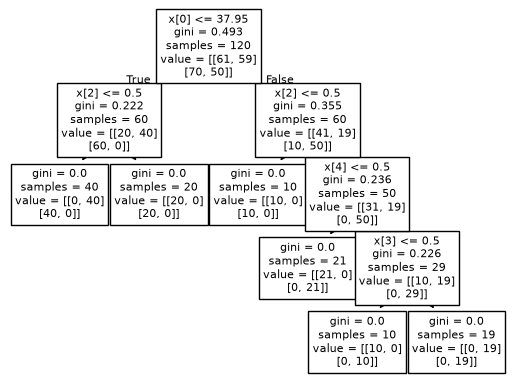

In [127]:
X = data_diagnosis.iloc[:, 0:6]
y = data_diagnosis.iloc[:, 6:8]

clf = DecisionTreeClassifier(random_state=37)
tree = plot_tree(clf.fit(X, y))

### (c) Convert the decision rules

In [128]:
def tree_to_pseudo(tree, feature_names):
	"""
	Outputs a decision tree model as if/then pseudocode
	
	Parameters:
	-----------
	tree: decision tree model
		The decision tree to represent as pseudocode
	feature_names: list
		The feature names of the dataset used for building the decision tree
	"""

	left = tree.tree_.children_left
	right = tree.tree_.children_right
	threshold = tree.tree_.threshold
	features = [feature_names[i] for i in tree.tree_.feature]
	value = tree.tree_.value

	def recurse(left, right, threshold, features, node, depth=0):
		indent = "  " * depth
		if (threshold[node] != -2):
			print(indent,"if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
			if left[node] != -1:
				recurse (left, right, threshold, features, left[node], depth+1)
				print(indent,"} else {")
				if right[node] != -1:
					recurse (left, right, threshold, features, right[node], depth+1)
				print(indent,"}")
		else:
			print(indent,"return " + str(value[node]))

	recurse(left, right, threshold, features, 0)

In [129]:
feature_names = list(X.columns)
tree_to_pseudo(clf, feature_names)

 if ( Temperature of patient <= 37.95000076293945 ) {
   if ( Lumbar pain <= 0.5 ) {
     return [[0. 1.]
 [1. 0.]]
   } else {
     return [[1. 0.]
 [1. 0.]]
   }
 } else {
   if ( Lumbar pain <= 0.5 ) {
     return [[1. 0.]
 [1. 0.]]
   } else {
     if ( Micturition pains <= 0.5 ) {
       return [[1. 0.]
 [0. 1.]]
     } else {
       if ( Urine pushing (continuous need for urination) <= 0.5 ) {
         return [[1. 0.]
 [0. 1.]]
       } else {
         return [[0. 1.]
 [0. 1.]]
       }
     }
   }
 }


### (d) Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability.

In [130]:
path = clf.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas
impurities = path.impurities

cv_errors = []

for alpha in ccp_alphas:
    clf_pruned = DecisionTreeClassifier(random_state=37, ccp_alpha=alpha)
    scores = cross_val_score(clf_pruned, X, y, cv=KFold(n_splits=5, shuffle=True, random_state=37), scoring='accuracy')
    cv_errors.append(1 - scores.mean())

best_alpha = ccp_alphas[np.argmin(cv_errors)]
clf_pruned = DecisionTreeClassifier(random_state=37, ccp_alpha=best_alpha)
clf_pruned.fit(X, y)
tree_to_pseudo(clf_pruned, feature_names)

 if ( Temperature of patient <= 37.95000076293945 ) {
   if ( Lumbar pain <= 0.5 ) {
     return [[0. 1.]
 [1. 0.]]
   } else {
     return [[1. 0.]
 [1. 0.]]
   }
 } else {
   if ( Lumbar pain <= 0.5 ) {
     return [[1. 0.]
 [1. 0.]]
   } else {
     if ( Micturition pains <= 0.5 ) {
       return [[1. 0.]
 [0. 1.]]
     } else {
       if ( Urine pushing (continuous need for urination) <= 0.5 ) {
         return [[1. 0.]
 [0. 1.]]
       } else {
         return [[0. 1.]
 [0. 1.]]
       }
     }
   }
 }


 if ( Temperature of patient <= 37.95000076293945 ) {
   if ( Lumbar pain <= 0.5 ) {
     return [[0. 1.]
 [1. 0.]]
   } else {
     return [[1. 0.]
 [1. 0.]]
   }
 } else {
   if ( Lumbar pain <= 0.5 ) {
     return [[1. 0.]
 [1. 0.]]
   } else {
     if ( Micturition pains <= 0.5 ) {
       return [[1. 0.]
 [0. 1.]]
     } else {
       if ( Urine pushing (continuous need for urination) <= 0.5 ) {
         return [[1. 0.]
 [0. 1.]]
       } else {
         return [[0. 1.]
 [0. 1.]]
       }
     }
   }
 }


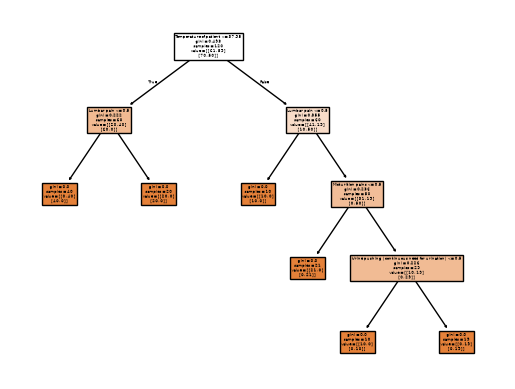

In [131]:
plot_tree(clf_pruned, feature_names=feature_names, filled=True)
tree_to_pseudo(clf_pruned, feature_names)

In [132]:
print('Selected alpha:', best_alpha)
print('Original leaves:', clf.get_n_leaves())
print('Selected tree leaves:', clf_pruned.get_n_leaves())

Selected alpha: 0.0
Original leaves: 6
Selected tree leaves: 6


Using 5-fold cross-validation, the optimal α was 0, meaning that pruning did not improve predictive performance compared to the original un-pruned tree. Thus, the selected tree and its decision rules remain unchanged from 1(b) and 1(c).

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [133]:
with open('../data/communities.names') as f:
    columns_communities = [line.split()[1] for line in f if line.startswith('@attribute')]
data_communities = pd.read_csv('../data/communities.csv', header=None, names=columns_communities)
data_communities

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,?,?,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,?,?,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,?,?,?,?,0.00,?,0.67
2,24,?,?,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,?,?,?,?,0.00,?,0.43
3,34,5,81440,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,?,?,?,?,0.00,?,0.12
4,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,?,?,?,?,0.00,?,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1989,12,?,?,TempleTerracecity,10,0.01,0.40,0.10,0.87,0.12,...,0.01,0.28,0.05,?,?,?,?,0.00,?,0.09
1990,6,?,?,Seasidecity,10,0.05,0.96,0.46,0.28,0.83,...,0.02,0.37,0.20,?,?,?,?,0.00,?,0.45
1991,9,9,80070,Waterburytown,10,0.16,0.37,0.25,0.69,0.04,...,0.08,0.32,0.18,0.08,0.06,0.78,0,0.91,0.28,0.23
1992,25,17,72600,Walthamcity,10,0.08,0.51,0.06,0.87,0.22,...,0.03,0.38,0.33,0.02,0.02,0.79,0,0.22,0.18,0.19


In [134]:
nonpredictive = ['state', 'county', 'community', 'communityname', 'fold']

X = data_communities.drop(columns=nonpredictive + ['ViolentCrimesPerPop'])
X = X.replace('?', np.nan).astype(float)
y = data_communities['ViolentCrimesPerPop']
X_train, X_test = X.iloc[:1495], X.iloc[1495:]
y_train, y_test = y.iloc[:1495], y.iloc[1495:]

### (b) Missing values

In [135]:
imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

### (c) Plot a correlation matrix

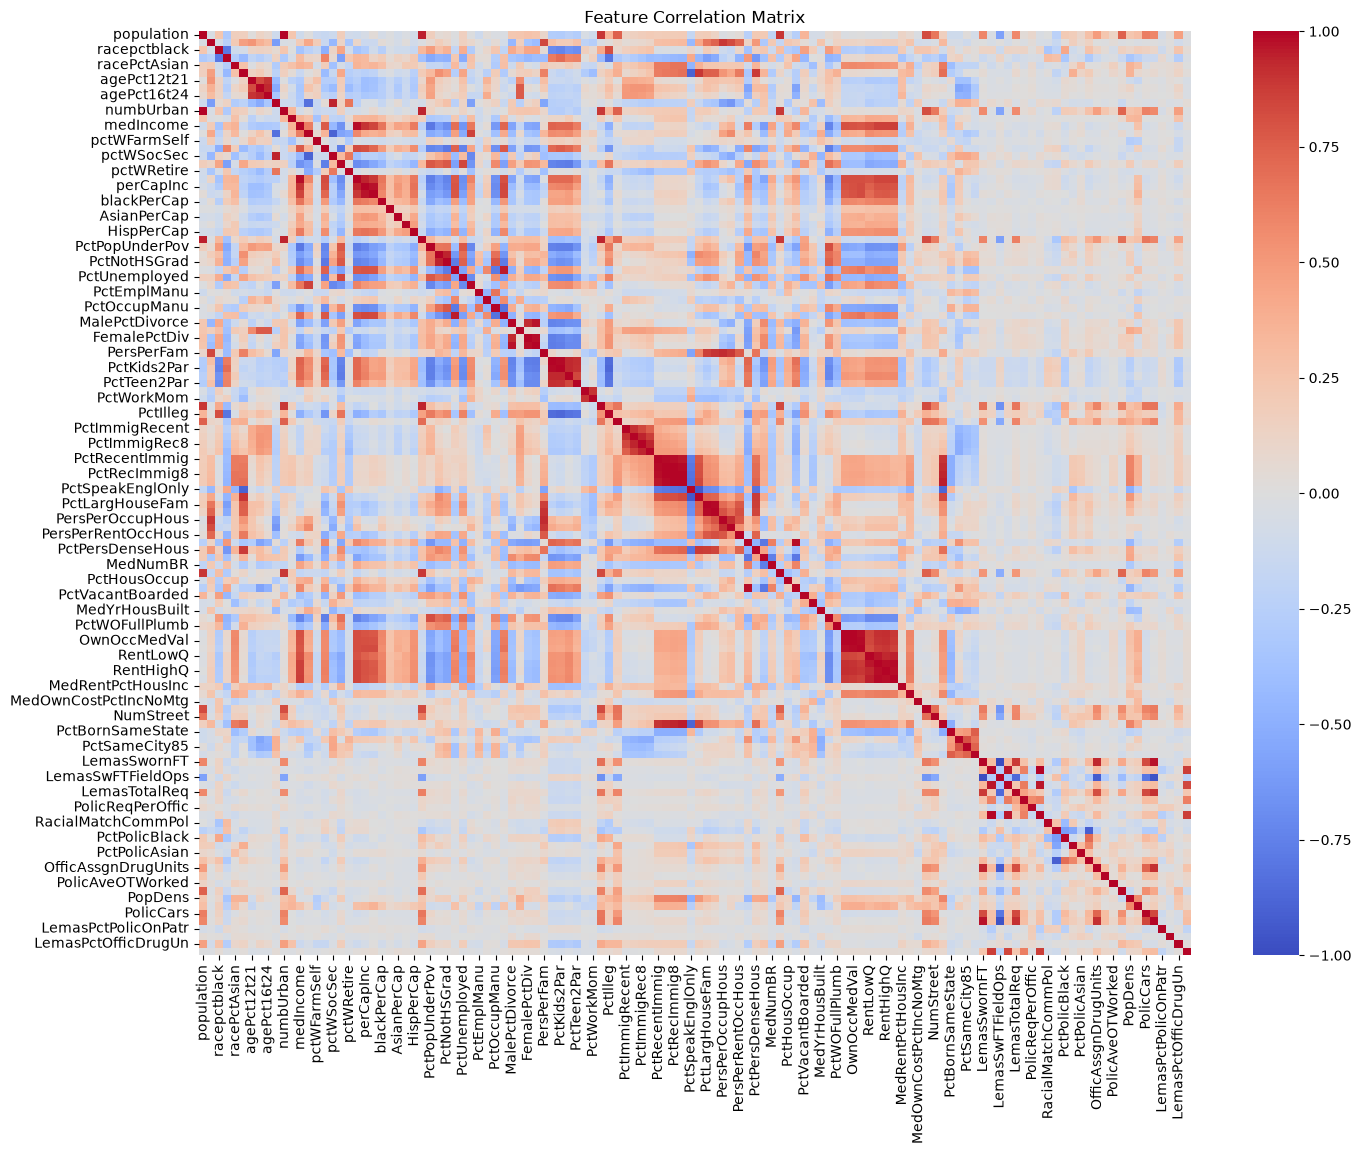

In [136]:
X_train_df = pd.DataFrame(X_train, columns=X.columns)

plt.figure(figsize=(16, 12))
sns.heatmap(X_train_df.corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix')
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [137]:
cv = X_train_df.std() / X_train_df.mean()
cv

population             2.241105
householdsize          0.355800
racepctblack           1.428885
racePctWhite           0.330213
racePctAsian           1.359100
                         ...   
PolicOperBudg          0.743487
LemasPctPolicOnPatr    0.115739
LemasGangUnitDeploy    0.362989
LemasPctOfficDrugUn    2.552946
PolicBudgPerPop        0.326026
Length: 122, dtype: float64

### (e) Scatter plots and box plots for highest CV features

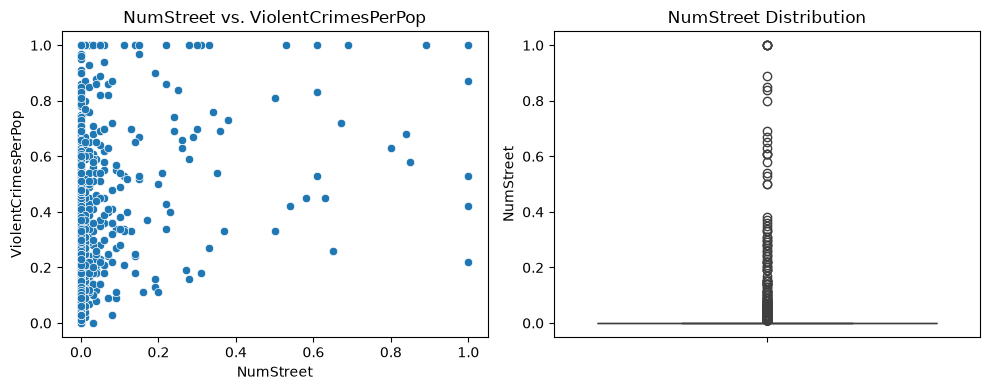

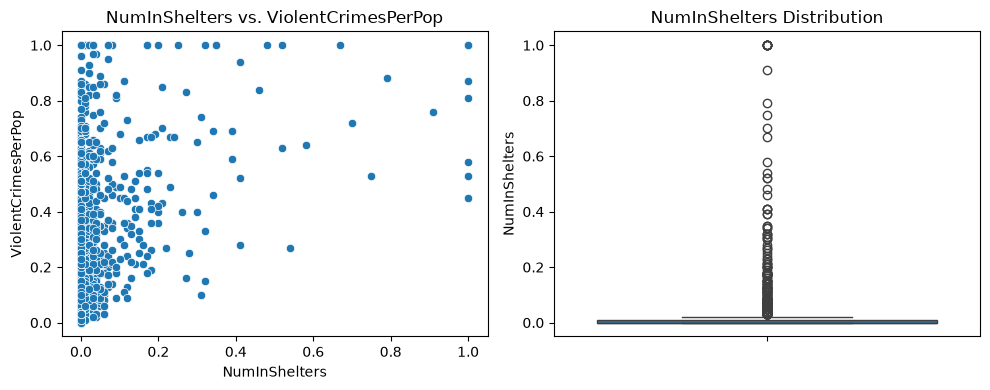

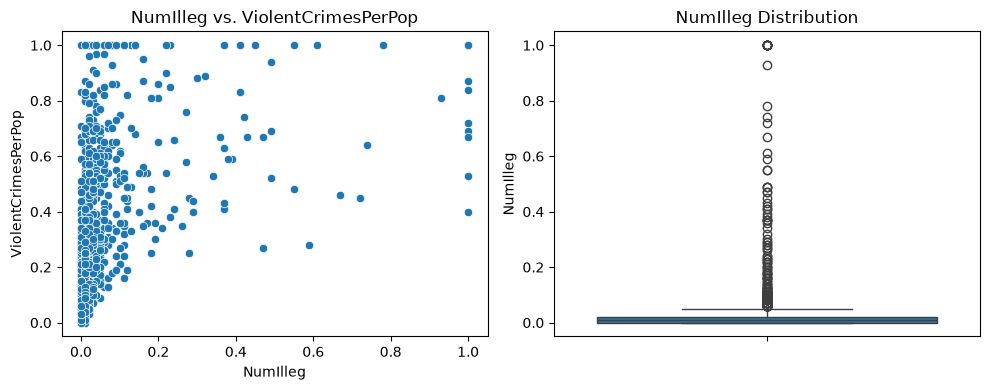

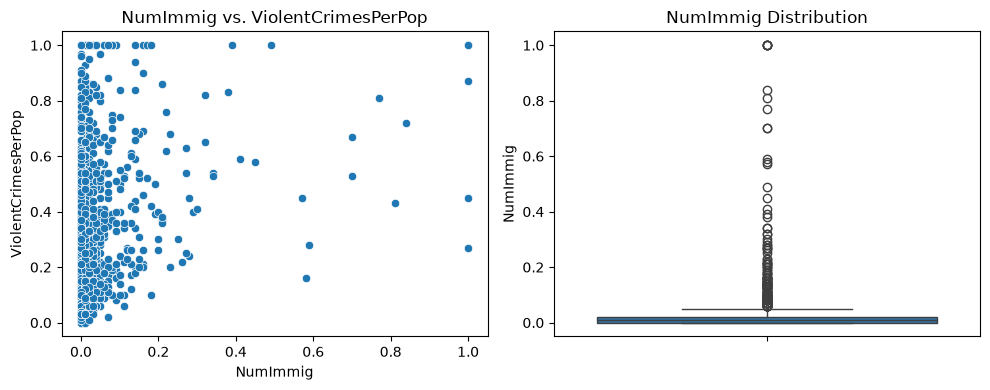

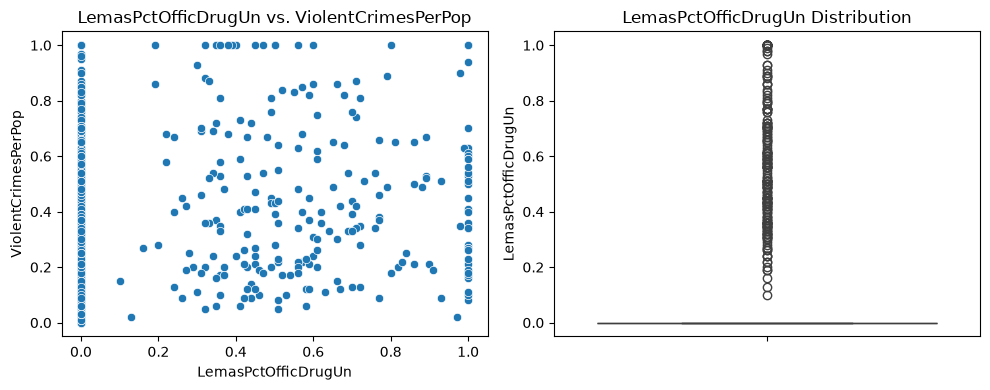

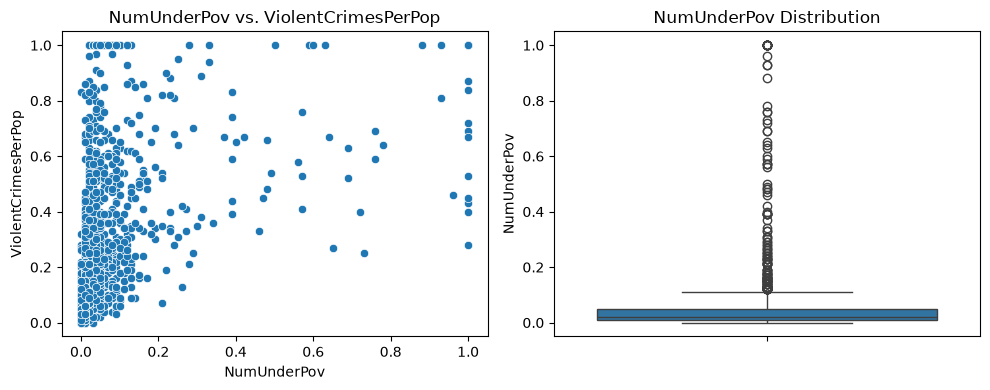

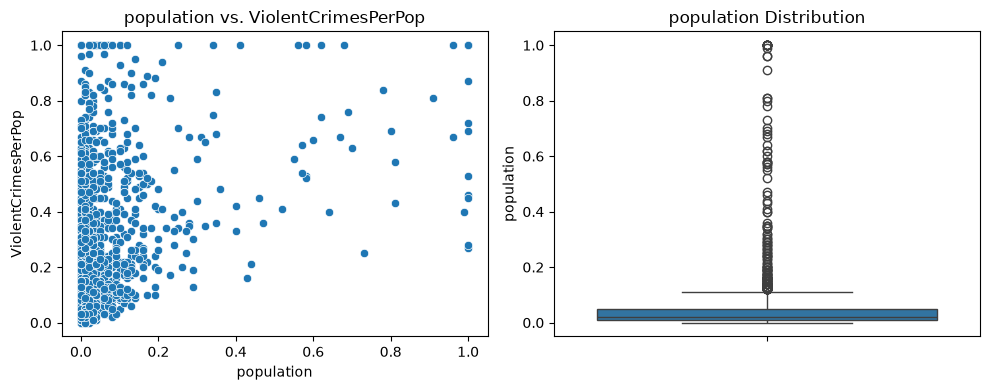

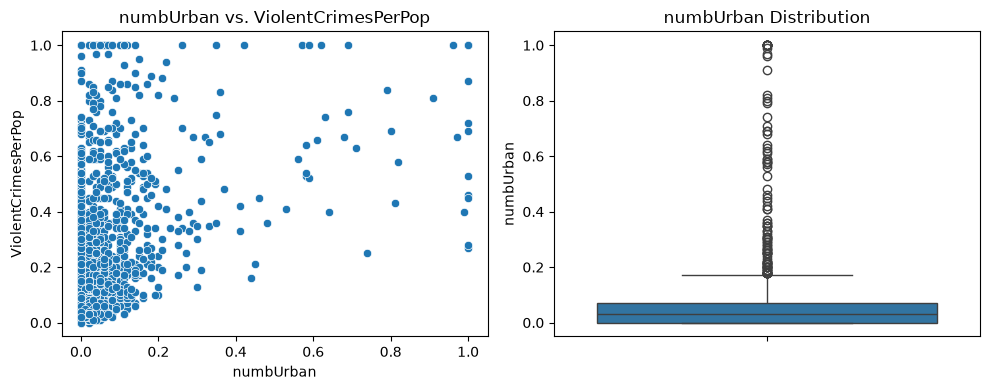

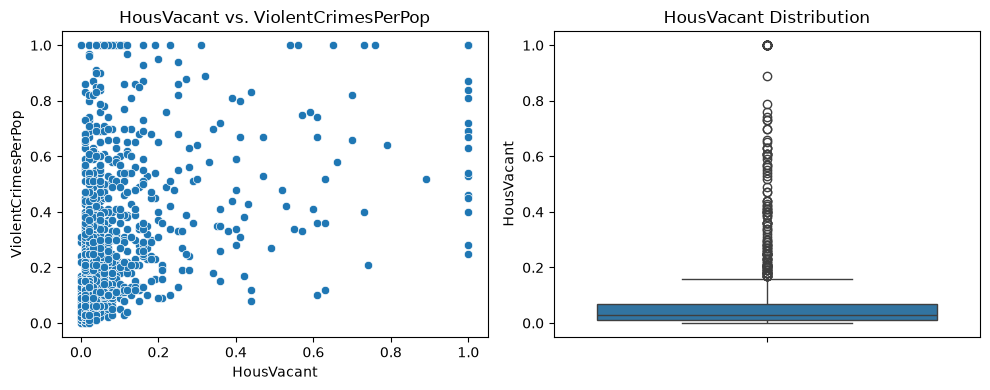

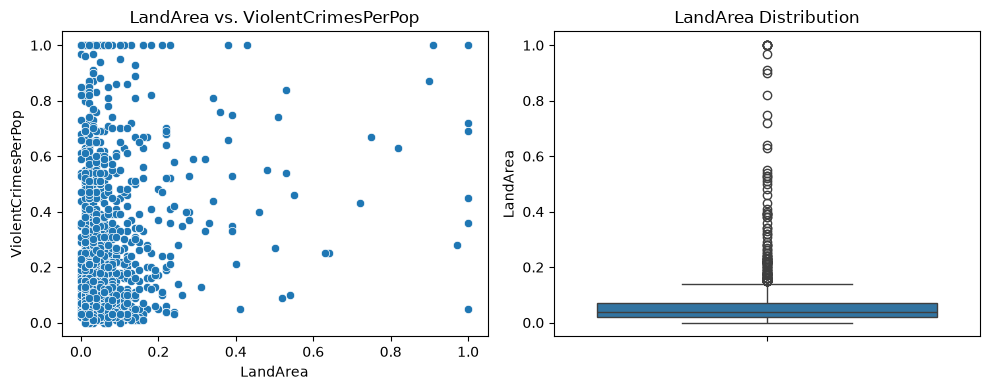

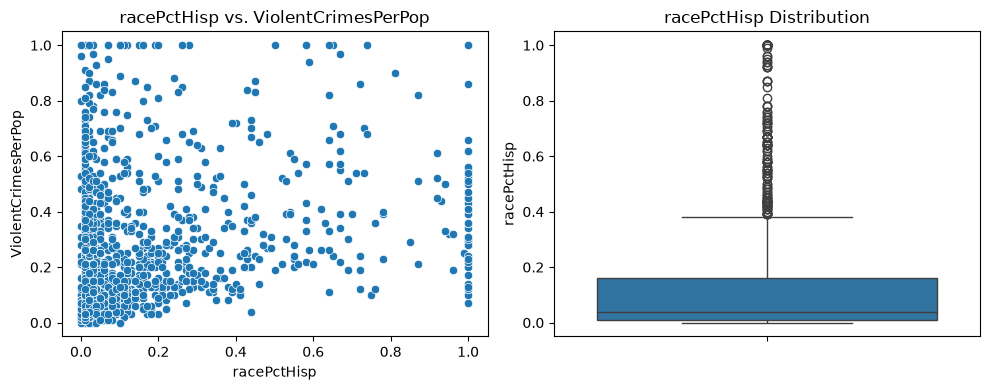

In [138]:
top_features = cv.nlargest(11).index

for feature in top_features:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    sns.scatterplot(x=X_train_df[feature], y=y_train.reset_index(drop=True), ax=axes[0])
    axes[0].set_title(f'{feature} vs. ViolentCrimesPerPop')
    sns.boxplot(y=X_train_df[feature], ax=axes[1])
    axes[1].set_title(f'{feature} Distribution')
    plt.tight_layout()
    plt.show()

#### Can you draw conclusions about significance of those features, just by the scatter plots?
No, just by judging from the scatterplots alone, you cannot draw any conclusions about the significance of those features. These scatterplots in this scenario do not implicate any relationships. Generally, scatterplots can reveal apparent relationships, but to conclude on statistical significance requires further testing beyond the scatterplots.

### (f) Fit a linear model

In [139]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred = linear_model.predict(X_test)
test_error = mean_squared_error(y_test, y_pred)
print('Test error:', test_error)

Test error: 0.018141971135530104


### (g) Fit a ridge regression model

In [140]:
ridge_model = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)
ridge_model.fit(X_train, y_train)
y_pred = ridge_model.predict(X_test)
test_error = mean_squared_error(y_test, y_pred)
print('Test error:', test_error)
print('Best lambda:', ridge_model.alpha_)

Test error: 0.01773247499289663
Best lambda: 1.0


### (h) Fit a LASSO model

In [141]:
lasso_model = LassoCV(alphas=[0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100], cv=5, max_iter=100000)
lasso_model.fit(X_train, y_train)
y_pred = lasso_model.predict(X_test)
test_error = mean_squared_error(y_test, y_pred)
print('Test error:', test_error)
print('Best lambda:', lasso_model.alpha_)
print('Feature names chosen by Lasso:', list(X.columns[lasso_model.coef_ != 0]))

Test error: 0.017786089519102124
Best lambda: 0.0001
Feature names chosen by Lasso: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInSh

#### Lasso with standardized features

In [142]:
features_standardized = StandardScaler().fit(X_train)
lasso_model_standardized = LassoCV(alphas=[0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100], cv=5, max_iter=100000)
lasso_model_standardized.fit(features_standardized.transform(X_train), y_train)
y_pred = lasso_model_standardized.predict(features_standardized.transform(X_test))
test_error = mean_squared_error(y_test, y_pred)
print('Test error:', test_error)
print('Best lambda:', lasso_model_standardized.alpha_)
print('Feature names chosen by Lasso:', list(X.columns[lasso_model_standardized.coef_ != 0]))

Test error: 0.017758149260213713
Best lambda: 0.001
Feature names chosen by Lasso: ['racepctblack', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasSwFTFieldPerPop', 'LemasTotalReq', 'PolicReqPerOffic', 'RacialMatchC

In [143]:
lasso_model_mse = mean_squared_error(y_test, lasso_model.predict(X_test))
lasso_model_standardized_mse = mean_squared_error(y_test, lasso_model_standardized.predict(features_standardized.transform(X_test)))
print('Lasso Model MSE:', lasso_model_mse)
print('Lasso Model Standardized MSE:', lasso_model_standardized_mse)

Lasso Model MSE: 0.017786089519102124
Lasso Model Standardized MSE: 0.017758149260213713


The test error for the lasso model without standardizing the features was .017786, whereas the test error for the lasso model with standardized features was also .017758. The MSE for the model without standardized features was higher. Thus, the lasso model using standardized features performed slightly better.

### (i) Fit a PCR model

In [144]:
pca = PCA()
linear_model_pca = Pipeline([('pca', pca), ('linear', LinearRegression())])

grid = GridSearchCV(linear_model_pca, {'pca__n_components': range(1, X_train.shape[1] + 1)}, cv=5, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)

linear_model_pca = grid.best_estimator_
y_pred = linear_model_pca.predict(X_test)
test_error = mean_squared_error(y_test, y_pred)
print('Test error with PCA:', test_error)

m = linear_model_pca.named_steps['pca'].n_components_
print('Number of components selected by PCA:', m)

Test error with PCA: 0.01847177851616756
Number of components selected by PCA: 96


### (j) Fit a boosting tree

In [145]:
lm_boost = XGBRegressor(n_estimators=1000, learning_rate=0.01, max_depth=3, random_state=37)
grid = GridSearchCV(lm_boost, {'reg_alpha': [0, 0.01, 0.1, 1, 10, 100]}, cv=5, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)
best_alpha = grid.best_params_['reg_alpha']
print('Best alpha:', best_alpha)

lm_boost = grid.best_estimator_
y_pred = lm_boost.predict(X_test)
test_error = mean_squared_error(y_test, y_pred)
print('Test error:', test_error)

Best alpha: 0.01
Test error: 0.016174849010549143
